# 01 - First Look at the Data (Omar, S1.12)

This notebook takes a first look at the processed sessions: how many are ready,
their shapes, neurons per brain region, choice balance, block counts, and the
error and zero-contrast trials. It uses the team modules
(`src.common.settings`, `src.analysis.eda`). No model is trained here.

## Plan

1. Load the configuration and list the processed sessions.
2. Summarise every ready session in one table.
3. Look at one session in detail: neurons per brain region.
4. Check the choice balance, the block prior and the control trials.
5. Look at the distribution of firing rates across neurons.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the brain-decoding repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.analysis.eda import block_counts, region_counts, summarize_sessions
from src.common.settings import load_config, list_processed_sessions, load_session

config = load_config()
print("Project:", config["project_name"])
print("Feature window (seconds):", config["data"]["window"])

Project: brain-decoding
Feature window (seconds): [-0.1, 0.0]


## 2. Which processed sessions are ready

In [2]:
ready = list(list_processed_sessions())
print("Processed sessions available:", len(ready))

if not ready:
    raise SystemExit(
        "No processed sessions found. "
        "Run: python -m src.data.build_dataset"
    )

sessions = [load_session(sid) for sid in ready]

Processed sessions available: 10


## 3. Summary of every session

In [3]:
summary = summarize_sessions(sessions)
display(summary)

,session_id,n_trials,n_neurons,n_regions,majority_class_rate,n_error_trials,n_zero_contrast_trials,rt_median,mean_rate_hz,silent_neuron_fraction
0,746d1902-fa59-4cab-b0aa-013be36060d5,481,429,17,0.561331,65,54,0.186565,12.609656,0.009324
1,ee40aece-cffd-4edb-a4b6-155f158c666a,527,427,15,0.599620,101,80,0.140153,9.572455,0.002342
2,f10efe41-0dc0-44d0-8f26-5ff68dca23e9,429,396,9,0.529138,60,50,0.195233,21.012220,0.022727
3,56b57c38-2699-4091-90a8-aba35103155e,415,391,13,0.561446,82,38,0.131999,14.113518,0.028133
4,4d8c7767-981c-4347-8e5e-5d5fffe38534,562,389,10,0.686833,132,68,0.303233,4.708578,0.025707
5,6274dda8-3a59-4aa1-95f8-a8a549c46a26,591,349,10,0.661591,57,60,0.149856,7.379654,0.011461
6,2bdf206a-820f-402f-920a-9e86cd5388a4,427,346,9,0.503513,63,47,0.148200,11.782161,0.005780
7,8207abc6-6b23-4762-92b4-82e05bed5143,491,332,8,0.541752,27,37,0.169332,7.575393,0.003012
8,dfbe628d-365b-461c-a07f-8b9911ba83aa,516,331,7,0.556202,67,57,0.218961,5.695801,0.015106
9,09394481-8dd2-4d5c-9327-f2753ede92d7,433,326,12,0.612009,87,53,0.115300,14.876167,0.036810


## 4. One session in detail

In [4]:
data = sessions[0]
x = np.asarray(data["X"], dtype=float)
print("Session:", str(data["session_id"]))
print("X shape (trials x neurons):", x.shape)
print("Fields:", sorted(data))

Session: 746d1902-fa59-4cab-b0aa-013be36060d5
X shape (trials x neurons): (481, 429)
Fields: ['X', 'contrast', 'is_error', 'is_zero_contrast', 'neuron_id', 'neuron_region', 'prob_left', 'reaction_time', 'session_id', 'stim_side', 'trial_number', 'y']


### Neurons per brain region

,neurons
PO,111
LP,72
IRN,45
VPLpc,43
GRN,34
MV,25
CUL4 5,22
ZI,19
VPM,15
NTS,9


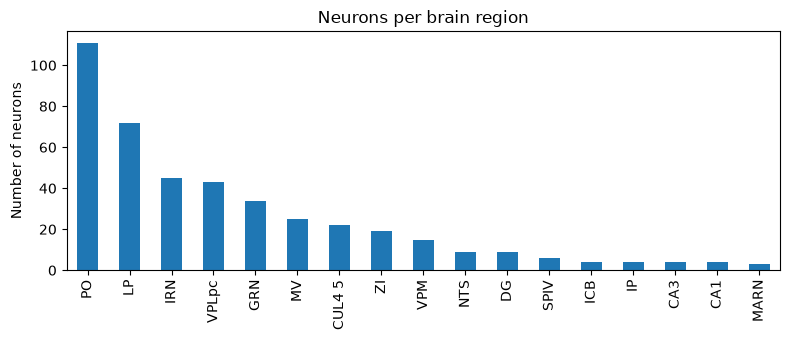

In [5]:
rc = region_counts(data)
display(rc.rename("neurons").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.5))
rc.plot.bar(ax=ax)
ax.set_ylabel("Number of neurons")
ax.set_title("Neurons per brain region")
plt.tight_layout()
plt.show()

### Choice balance, block prior and control trials

In [6]:
y = np.asarray(data["y"])
print("Trials:", len(y))
print("Choice balance (mean of y):", round(float(y.mean()), 3))
print("Error trials:", int(np.sum(data["is_error"])))
print("Zero-contrast trials:", int(np.sum(data["is_zero_contrast"])))
display(block_counts(data).rename("trials").to_frame())

Trials: 481
Choice balance (mean of y): 0.439
Error trials: 65
Zero-contrast trials: 54


,trials
0.2,196
0.5,69
0.8,216


### Firing rates

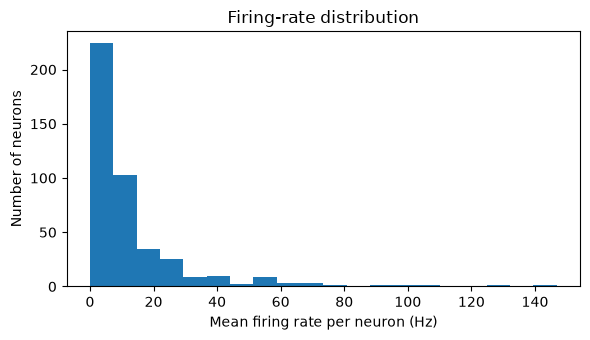

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(x.mean(axis=0), bins=20)
ax.set_xlabel("Mean firing rate per neuron (Hz)")
ax.set_ylabel("Number of neurons")
ax.set_title("Firing-rate distribution")
plt.tight_layout()
plt.show()

## Conclusions

No result is claimed in this notebook. Every number above comes from the
processed sessions built by S1.7. Re-run the notebook whenever the session
list changes.